# 11 · 主波眨眼候选复核

窗口显示橙色主波和本轮复核标记，并恢复flash事件竖线：红色为target，绿色为non-target，灰色为未知标签。旧候选区间、恢复区间和历史标注仍隐藏。使用 `BAD` 标记你认为多检的部分，再点击“保存窗口复核”。

原始EDF、自动检测参数和已有人工标注不变。主波边界仍是待复核估计，并不代表主波结束后信号一定干净。如果旧窗口还有未保存标记，请先使用下面的补存单元，不要先重启内核或运行全部单元。


## 已经用BAD画过标记：先补存

仅在原来的内核和窗口仍在时，单独运行下一格。它重新加载已修复的保存函数，尝试保存当前窗口中的 `BAD`、`bad`、`BAD_*` 或 `REVIEW_*` 标记。

如果提示没有活动窗口或没有标记，就没有保存成功；磁盘空文件不能恢复已经丢失的内存标记。补存成功后，再重新运行第3节面板。


In [1]:
from pathlib import Path
import sys,importlib
_rescue_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
if str(_rescue_root/'src') not in sys.path:sys.path.insert(0,str(_rescue_root/'src'))
import bigp3bci_candidate_review as candidate_review
importlib.reload(candidate_review)
_existing_panel=globals().get('panel_state',{})
_existing_raw=_existing_panel.get('raw')
if _existing_raw is None:
    _existing_raw=globals().get('browser_raw')
if _existing_raw is None:
    print('未找到当前内核中的复核窗口；本单元没有写文件。首次使用可继续运行后面的单元。')
else:
    from collections import Counter
    print('当前窗口标签：',dict(Counter(map(str,_existing_raw.annotations.description))))
    _n=sum(candidate_review.normalize_review_label(label) is not None and duration>0 for label,duration in zip(_existing_raw.annotations.description,_existing_raw.annotations.duration))
    if not _n:
        print('当前对象没有可保存的BAD或REVIEW标记，未覆盖磁盘文件。')
    else:
        _edf=getattr(_existing_raw,'_blink_review_edf',None)
        _csv,_fif,_spans=candidate_review.save_review_spans(_rescue_root,_edf,_existing_raw)
        if _existing_panel.get('raw') is _existing_raw and '_span_signature' in globals():
            _existing_panel['saved_signature']=_span_signature(_existing_raw)
        print('成功补存',_n,'段：',_fif)
        print('候选复核表：',_csv)
        display(_spans)


未找到当前内核中的复核窗口；本单元没有写文件。首次使用可继续运行后面的单元。


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
if str(ROOT/'src') not in sys.path:sys.path.insert(0,str(ROOT/'src'))
from bigp3bci_candidate_review import load_candidate_review,open_candidate_review
INDEX=pd.read_csv(ROOT/'outputs/blink_candidate_review/file_index.csv')
display(INDEX[['edf_name','candidate_count','nonstartup_candidates','annotation_reload_verified']])


,edf_name,candidate_count,nonstartup_candidates,annotation_reload_verified
0,F_03_SE001_CBCol_Train01.edf,3,2,True
1,F_03_SE002_CBCol_Train01.edf,6,3,True
2,F_05_SE001_CBCol_Train02.edf,95,91,True
3,F_05_SE002_CBCol_Train01.edf,102,97,True
4,F_06_SE001_CBCol_Train01.edf,2,2,True
5,F_06_SE002_CBCol_Train01.edf,0,0,True
6,F_20_SE001_CBCol_Train01.edf,6,6,True
7,F_20_SE002_CBCol_Train01.edf,12,11,True
8,F_05_SE002_CBCol_Train02.edf,126,123,True
9,F_05_SE003_CBCol_Train04.edf,140,133,True


## 1. 选择文件和波形

这里只叠加新版主波。`raw` 为原始EEG，便于查看上升和回落；`analysis` 为正式因果滤波信号，`auxiliary` 为旧检测器的辅助分支。切换波形不会移动标注或修改参数。

下面先生成静态预览；交互窗口在第3节打开。


In [3]:
EDF_NAME='F_05_SE003_CBCol_Train04.edf'
MODE='raw'
START_SECONDS=10.0
DURATION_SECONDS=12.0
review_raw,flash_events,candidates,review_csv=load_candidate_review(ROOT,EDF_NAME,MODE,include_manual=False,main_only=True)
display(candidates[['blink_candidate_id','onset_seconds','peak_seconds','offset_seconds','filter_startup','localization_flags']].head(20))
print('候选复核表：',review_csv)


,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,filter_startup,localization_flags
0,F_05_SE003_CBCol_Train04_B0001,0.570312,0.906250,1.519531,True,possible_adjacent_main_lobes
1,F_05_SE003_CBCol_Train04_B0002,1.894531,2.046875,2.445312,True,possible_adjacent_main_lobes
2,F_05_SE003_CBCol_Train04_B0003,2.433594,2.492188,2.582031,True,
3,F_05_SE003_CBCol_Train04_B0004,3.515625,3.605469,4.410156,True,main_offset_unconfirmed
4,F_05_SE003_CBCol_Train04_B0005,6.671875,6.746094,6.886719,True,
5,F_05_SE003_CBCol_Train04_B0006,6.875000,7.207031,7.671875,True,
6,F_05_SE003_CBCol_Train04_B0007,8.617188,8.710938,8.894531,True,
7,F_05_SE003_CBCol_Train04_B0008,11.292969,11.359375,11.480469,False,
8,F_05_SE003_CBCol_Train04_B0009,13.500000,13.617188,13.777344,False,
9,F_05_SE003_CBCol_Train04_B0010,13.781250,14.191406,14.996094,False,main_offset_unconfirmed;main_duration_outside_...


候选复核表： D:\BCI_project\bigp3bci-personalized-strategies\outputs\blink_candidate_review\F_05_SE003_CBCol_Train04\review_decisions.csv


## 2. 主波静态预览

橙色区间为暂定主波；其他彩色区间仅为本轮已保存的复核标记。主波边界仍需人工检查，不表示其后恢复区间没有污染。


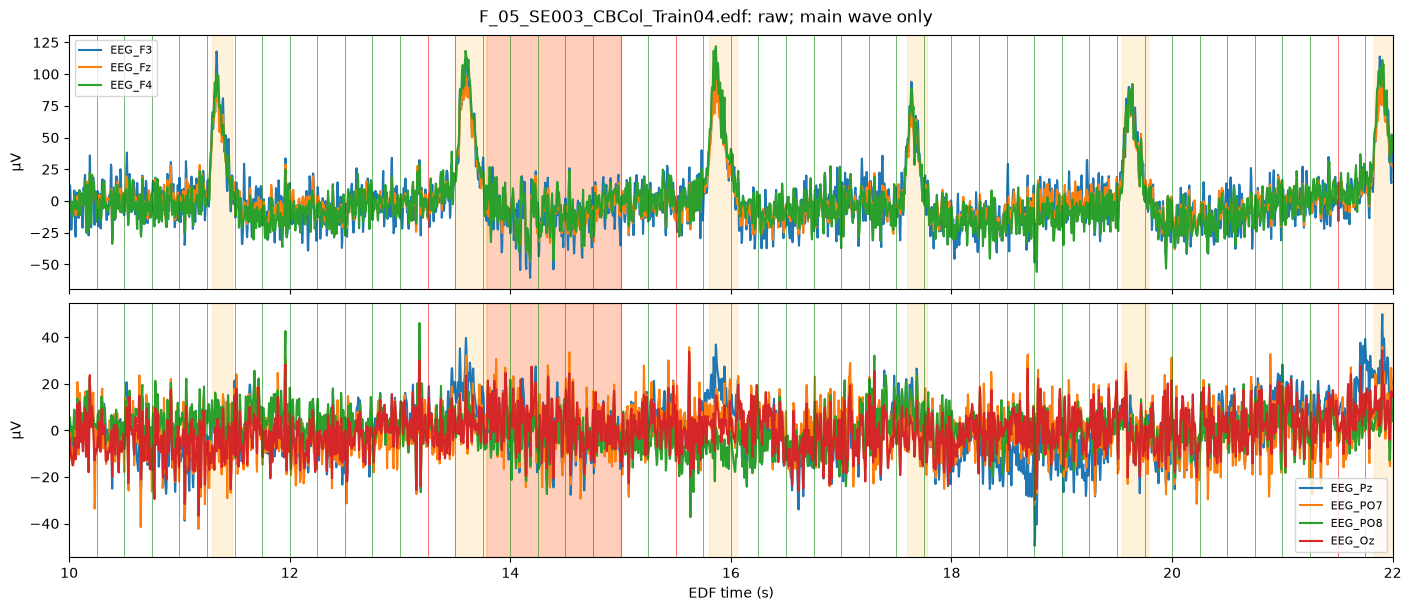

In [4]:
fs=float(review_raw.info['sfreq'])
a=round(START_SECONDS*fs);b=min(review_raw.n_times,a+round(DURATION_SECONDS*fs))
fig,axes=plt.subplots(2,1,figsize=(14,6),sharex=True,layout='constrained')
for ax,names in zip(axes,[['EEG_F3','EEG_Fz','EEG_F4'],['EEG_Pz','EEG_PO7','EEG_PO8','EEG_Oz']]):
    values=review_raw.get_data(picks=names,start=a,stop=b)*1e6
    for name,v in zip(names,values):ax.plot(np.arange(a,b)/fs,v,label=name)
    for on,duration,label in zip(review_raw.annotations.onset,review_raw.annotations.duration,review_raw.annotations.description):
        if on<b/fs and on+duration>a/fs and str(label).startswith(('CANDIDATE_blink_main','REVIEW_')):
            ax.axvspan(on,on+duration,alpha=.14,color='orange' if label=='CANDIDATE_blink_main' else 'red')
    for sample,_,event_code in flash_events:
        if a<=sample<b:
            ax.axvline(sample/fs,color={1:'green',2:'red',3:'gray'}.get(int(event_code),'gray'),lw=.6,alpha=.65)
    ax.set(ylabel='µV',xlim=(a/fs,b/fs));ax.legend(fontsize=8)
axes[-1].set_xlabel('EDF time (s)')
fig.suptitle(f'{EDF_NAME}: {MODE}; main wave only')
plt.show()


## 3. 交互窗口：抽选文件并标记“多检”

运行下一格出现控制面板，选择EDF、波形模式和候选，点击 **打开/定位候选** 即弹出16通道可滚动窗口。程序使用已安装的PyQt5与MNE matplotlib浏览器，不需要额外安装mne-qt-browser。可先查看原始EEG，再切到analysis/auxiliary对照；检测参数不变。

**两种复核方法：**

- 对完整候选下结论：选择候选后点“多检/不是眨眼”“确认眨眼”或“不确定”。自动单独保存该ID的复核决定，并在内存中加红色REVIEW标记。
- 在窗口里划片段：按 `a` 进入annotation模式，新建标签 `REVIEW_not_blink`（多检），也可使用 `REVIEW_confirmed_blink`、`REVIEW_uncertain`。拖出区间后点面板的“保存窗口复核”。区间包含候选峰时，决定才会关联到该候选ID；没包含峰的片段仍保存，但需你核对对应关系。

**不要直接删除橙色主波来表示多检。** 可以直接使用默认的 `BAD` 标签标记多检，再点击“保存窗口复核”。显示橙色主波、本轮复核标记和flash竖线（红色target、绿色non-target、灰色未知）；旧区间、恢复区间和历史标注隐藏。主波复核单独保存，不覆盖EDF、自动候选或历史人工标注。再次打开会恢复已保存的主波复核标记。已有冲突决定保守记为uncertain，需在CSV中明确更正。

切换窗口前先保存；有未保存的REVIEW区间时程序会阻止切换。只检查选中候选不代表整段完整检查，不会自动增加reviewed_intervals。


In [ ]:
import ipywidgets as widgets
import importlib
import mne
import bigp3bci_candidate_review as candidate_review
importlib.reload(candidate_review)
from IPython.display import display,clear_output

panel_file=widgets.Dropdown(options=INDEX.edf_name.tolist(),value=EDF_NAME,description='EDF:',layout=widgets.Layout(width='560px'))
panel_mode=widgets.Dropdown(options=['raw','analysis','auxiliary'],value='raw',description='波形:')
panel_candidate=widgets.Dropdown(description='候选:',layout=widgets.Layout(width='560px'))
panel_notes=widgets.Text(value='',description='备注:',layout=widgets.Layout(width='650px'))
open_button=widgets.Button(description='打开/定位候选',button_style='primary')
false_button=widgets.Button(description='多检/不是眨眼',button_style='danger')
true_button=widgets.Button(description='确认眨眼',button_style='success')
uncertain_button=widgets.Button(description='不确定')
save_button=widgets.Button(description='保存窗口复核',button_style='info')
panel_output=widgets.Output()
panel_state={'raw':None,'browser':None,'edf':None,'saved_signature':None,'candidates':None}

def _span_signature(raw):
    if raw is None:return ()
    return tuple((round(float(a),6),round(float(d),6),str(label))
                 for a,d,label in zip(raw.annotations.onset,raw.annotations.duration,raw.annotations.description)
                 if candidate_review.normalize_review_label(label) is not None and d>0)

def _refresh_candidates(change=None):
    entry=INDEX[INDEX.edf_name.eq(panel_file.value)].iloc[0]
    c=pd.read_csv(ROOT/entry.candidate_details_csv)
    boundary=pd.read_csv(ROOT/'outputs/blink_boundary_localization_v1'/Path(panel_file.value).stem/'boundaries.csv')
    for target,source in [('onset_seconds','main_onset_seconds'),('peak_seconds','main_peak_seconds'),('offset_seconds','main_offset_seconds')]:c[target]=boundary[source].to_numpy(float)
    panel_state['candidates']=c
    panel_candidate.options=[(f'{r.blink_candidate_id.split("_B")[-1]} | {r.onset_seconds:.3f}–{r.offset_seconds:.3f}s'+(' 启动期' if r.filter_startup else ''),r.blink_candidate_id) for r in c.itertuples()]
    eligible=c[c.filter_startup.eq(False)]
    if len(eligible):panel_candidate.value=eligible.iloc[0].blink_candidate_id

panel_file.observe(_refresh_candidates,names='value')
_refresh_candidates()

def _selected_candidate():
    c=panel_state['candidates']
    selected=c[c.blink_candidate_id.eq(panel_candidate.value)]
    return None if selected.empty else selected.iloc[0]

def _open_window(button):
    with panel_output:
        clear_output(wait=True)
        try:
            current=panel_state['raw']
            if current is not None and _span_signature(current)!=panel_state['saved_signature']:
                raise RuntimeError('当前窗口有未保存REVIEW区间，请先点“保存窗口复核”。')
            get_ipython().run_line_magic('matplotlib','qt')
            mne.viz.set_browser_backend('matplotlib')
            if panel_state['browser'] is not None:
                plt.close(panel_state['browser'])
            if current is not None:current.close()
            selected=_selected_candidate()
            start=START_SECONDS if selected is None else max(0.,selected.onset_seconds-2.)
            raw,browser,_,_=candidate_review.open_candidate_review(ROOT,panel_file.value,mode=panel_mode.value,start=start,duration=12.,include_manual=False,main_only=True)
            panel_state.update(raw=raw,browser=browser,edf=panel_file.value,saved_signature=_span_signature(raw))
            print(f'已打开 {panel_file.value} / {panel_mode.value}，起点 {start:.3f}s。')
            print('按a进入标注；新建REVIEW_not_blink标多检，完成后点保存窗口复核。')
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

def _save_window(button=None):
    raw=panel_state['raw']
    if raw is None:raise RuntimeError('请先打开一个文件窗口。')
    path,annotation,spans=candidate_review.save_review_spans(ROOT,panel_state['edf'],raw)
    panel_state['saved_signature']=_span_signature(raw)
    print('已保存：',path)
    print('本轮人工区间：',annotation)
    if len(spans):display(spans.tail(8))
    empty=spans[spans.blink_candidate_ids.eq('')]
    if len(empty):print('注意：',len(empty),'个区间未包含任何候选峰，已保留区间但未写候选决定。')

def _save_clicked(button):
    with panel_output:
        clear_output(wait=True)
        try:_save_window()
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

def _decide(label):
    with panel_output:
        clear_output(wait=True)
        try:
            if panel_state['raw'] is None or panel_state['edf']!=panel_file.value:
                raise RuntimeError('请先打开当前选择的EDF。')
            selected=_selected_candidate()
            if selected is None:raise RuntimeError('当前文件没有候选。')
            raw=panel_state['raw']
            raw.set_annotations(raw.annotations+mne.Annotations([selected.onset_seconds],[selected.offset_seconds-selected.onset_seconds],[label],orig_time=raw.annotations.orig_time))
            _save_window()
            if panel_notes.value.strip():
                entry=INDEX[INDEX.edf_name.eq(panel_file.value)].iloc[0]
                path=ROOT/entry.review_decisions_csv
                d=pd.read_csv(path,keep_default_na=False)
                mask=d.blink_candidate_id.eq(selected.blink_candidate_id)
                d.loc[mask,'review_notes']=d.loc[mask,'review_notes'].astype(str)+'; '+panel_notes.value.strip()
                d.to_csv(path,index=False)
            print(selected.blink_candidate_id,'→',candidate_review.REVIEW_DECISIONS[label])
            print('可选择下一候选，点击“打开/定位候选”跳转。')
        except Exception as exc:print(type(exc).__name__+': '+str(exc))

open_button.on_click(_open_window)
save_button.on_click(_save_clicked)
false_button.on_click(lambda b:_decide('REVIEW_not_blink'))
true_button.on_click(lambda b:_decide('REVIEW_confirmed_blink'))
uncertain_button.on_click(lambda b:_decide('REVIEW_uncertain'))
display(widgets.VBox([panel_file,panel_mode,panel_candidate,panel_notes,
    widgets.HBox([open_button,save_button]),widgets.HBox([false_button,true_button,uncertain_button]),panel_output]))


## 4. 保存位置

主波复核单独保存在：

- `*-human-main-review-annot.fif`：本轮人工复核时间段。
- `human_main_review_spans.csv`：复核时间段及对应的候选ID。
- `review_decisions.csv`：按候选ID记录复核决定，`review_region=main` 表示复核的是主波。

旧复核文件不会被覆盖。切换文件或关闭窗口前，请先点击“保存窗口复核”，并确认下方显示保存成功。


In [6]:
display(pd.read_csv(review_csv,keep_default_na=False).head(15))
review_raw.close()
assert INDEX.annotation_reload_verified.all()
print('主波复核入口已准备好，原始EDF及历史标注未修改。')


,edf_name,blink_candidate_id,onset_seconds,peak_seconds,offset_seconds,decision_seconds,filter_startup,review_decision,review_notes,review_region
0,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0001,0.902344,0.941406,1.339844,1.492188,True,,,
1,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0002,1.800781,1.855469,2.132812,2.285156,True,not_blink,,main
2,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0003,2.437500,2.507812,3.097656,3.250000,True,not_blink,,main
3,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0004,3.582031,3.625000,4.296875,4.449219,True,not_blink,,main
4,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0005,6.707031,6.964844,7.195312,7.347656,True,,,
5,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0006,7.417969,7.738281,8.128906,8.281250,True,not_blink,,main
6,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0007,8.660156,8.730469,9.148438,9.300781,True,,,
7,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0008,11.328125,11.382812,11.734375,11.886719,False,,,
8,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0009,13.574219,13.832031,14.035156,14.187500,False,,,
9,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0010,14.250000,14.371094,14.621094,14.773438,False,not_blink,,main


主波复核入口已准备好，原始EDF及历史标注未修改。
